In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Import dataset into dataframes**

**READ ME** <br>
Important mounting procedure:
Please create a Google Drive Folder under your MyDrive named '**Diabetes_Project**' <br>
Upload the datasets<br>
Continue mounting the Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/Diabetes_Project

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Diabetes_Project


In [ ]:
# Patients Data
patient_df = pd.read_csv("diabetic_data.csv")
patient_df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:

mapping_df = pd.read_csv("IDS_mapping.csv")

# Identify rows that are completely null/empty
is_null_row = mapping_df.isnull().all(axis=1)

# Create group IDs by taking the cumulative sum of the null row markers
group_id = is_null_row.cumsum()

# Split into separate DataFrames, dropping the empty/null rows themselves
dataframes = []
for gid, group in mapping_df.groupby(group_id):
    # Drop rows that are entirely NaN within the group
    clean_group = group.dropna(how='all')

    if not clean_group.empty:
        # Optionally promote the first row of each sub-table as the header
        clean_group = clean_group.reset_index(drop=True)
        header = clean_group.iloc[0]
        df_table = pd.DataFrame(clean_group.values[1:], columns=header)
        dataframes.append(df_table)

print(f"Extracted {len(dataframes)} tables successfully.")

# Promote columns in the first dataframe
dataframes[0] = pd.concat([dataframes[0].columns.to_frame().T, dataframes[0]])
dataframes[0].columns = ['admission_type_id', 'description']
admission_type_map_df = dataframes[0]

# Renaming dataframes
discharge_disposition_df = dataframes[1]
admission_source_df = dataframes[2]

Extracted 3 tables successfully.


In [ ]:
patient_df.shape

(101766, 50)

In [ ]:
patient_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
patient_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983458,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,101766,6,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,101766,10,?,98569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


In [ ]:
# Actual NaN values
patient_df.isnull().sum().sort_values(ascending=False)

,0
max_glu_serum,96420
A1Cresult,84748
race,0
gender,0
age,0
weight,0
admission_type_id,0
discharge_disposition_id,0
admission_source_id,0
time_in_hospital,0


In [ ]:
# Missing values represented as "?"
(patient_df == '?').sum().sort_values(ascending=False)

,0
weight,98569
medical_specialty,49949
payer_code,40256
race,2273
diag_3,1423
diag_2,358
diag_1,21
admission_type_id,0
patient_nbr,0
encounter_id,0


In [ ]:
missing_summary = pd.DataFrame({
    'NaN_Count': patient_df.isnull().sum(),
    'Question_Mark_Count': (patient_df == '?').sum()
})

missing_summary['Total_Missing'] = (
    missing_summary['NaN_Count'] +
    missing_summary['Question_Mark_Count']
)

missing_summary['Missing_Percentage'] = (
    missing_summary['Total_Missing'] / len(patient_df) * 100
)

missing_summary.sort_values(
    'Missing_Percentage',
    ascending=False
).head(15)

,NaN_Count,Question_Mark_Count,Total_Missing,Missing_Percentage
weight,0,98569,98569,96.858479
max_glu_serum,96420,0,96420,94.746772
A1Cresult,84748,0,84748,83.277322
medical_specialty,0,49949,49949,49.082208
payer_code,0,40256,40256,39.557416
race,0,2273,2273,2.233555
diag_3,0,1423,1423,1.398306
diag_2,0,358,358,0.351787
diag_1,0,21,21,0.020636
patient_nbr,0,0,0,0.000000


In [ ]:
print("Duplicate rows:", patient_df.duplicated().sum())

Duplicate rows: 0


In [ ]:
patient_df.nunique().sort_values()

,0
citoglipton,1
examide,1
acetohexamide,2
glipizide-metformin,2
tolbutamide,2
troglitazone,2
metformin-rosiglitazone,2
glimepiride-pioglitazone,2
metformin-pioglitazone,2
change,2


In [ ]:
patient_df['readmitted'].value_counts()

,count
readmitted,
NO,54864
>30,35545
<30,11357


In [ ]:
patient_df['readmitted'].value_counts(normalize=True) * 100

,proportion
readmitted,
NO,53.911916
>30,34.928169
<30,11.159916


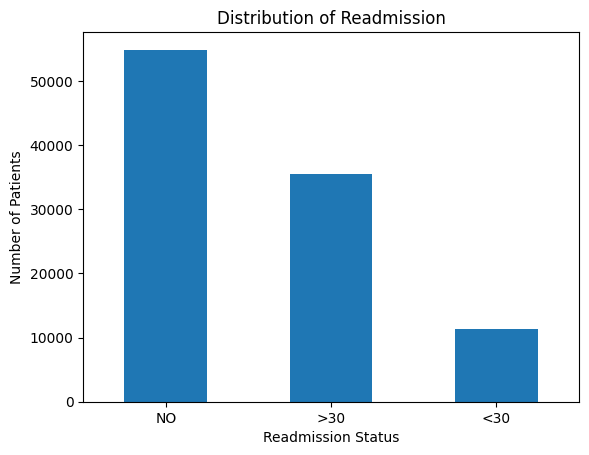

In [ ]:
import matplotlib.pyplot as plt

patient_df['readmitted'].value_counts().plot(kind='bar')

plt.title('Distribution of Readmission')
plt.xlabel('Readmission Status')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)

plt.show()

In [ ]:
age_order = [
    '[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)',
    '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)'
]

age_counts = patient_df['age'].value_counts().reindex(age_order)

age_counts

,count
age,
[0-10),161
[10-20),691
[20-30),1657
[30-40),3775
[40-50),9685
[50-60),17256
[60-70),22483
[70-80),26068
[80-90),17197


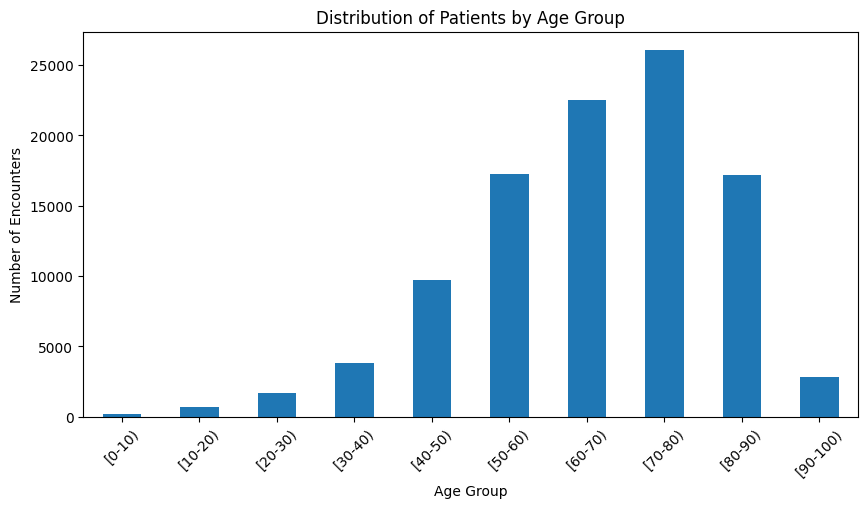

In [ ]:
plt.figure(figsize=(10, 5))

age_counts.plot(kind='bar')

plt.title('Distribution of Patients by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Encounters')
plt.xticks(rotation=45)

plt.show()

In [ ]:
age_readmission = pd.crosstab(
    patient_df['age'],
    patient_df['readmitted'],
    normalize='index'
) * 100

age_readmission = age_readmission.reindex(age_order)

age_readmission

readmitted,<30,>30,NO
age,,,
[0-10),1.863354,16.149068,81.987578
[10-20),5.788712,32.416787,61.794501
[20-30),14.242607,30.778515,54.978877
[30-40),11.231788,31.443709,57.324503
[40-50),10.604027,33.846154,55.549819
[50-60),9.666203,34.289522,56.044274
[60-70),11.128408,35.124316,53.747276
[70-80),11.773055,36.347246,51.879699
[80-90),12.083503,36.186544,51.729953


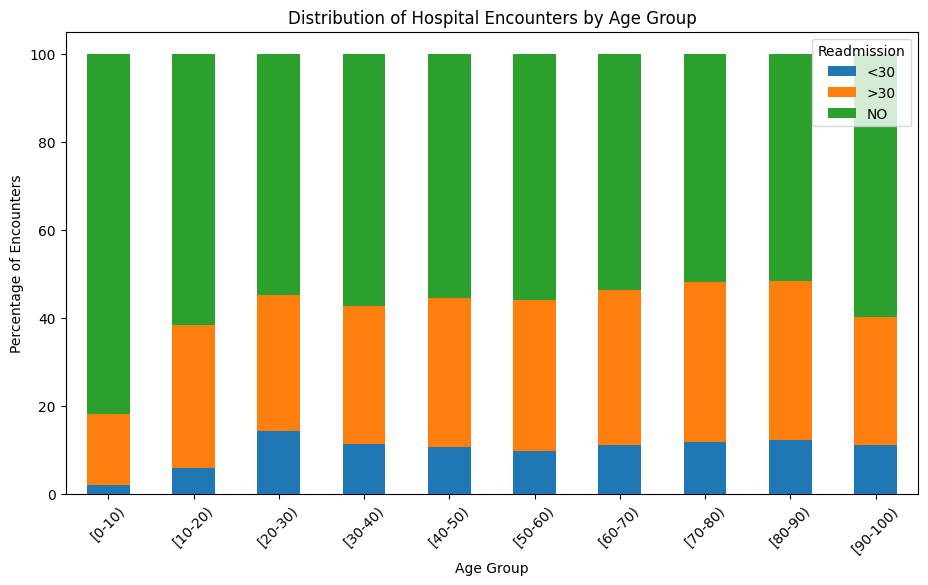

In [ ]:
age_readmission.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Readmission Status by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Percentage of Encounters')
plt.xticks(rotation=45)
plt.legend(title='Readmission')
plt.title('Distribution of Hospital Encounters by Age Group')

plt.show()

Observation: The dataset is dominated by older patients, with the [70-80) age group containing the largest number of encounters. When readmission status is examined as a percentage within each age group, longer-term (>30 days) readmission generally becomes more common from middle age through the older age groups, reaching approximately 36% among patients aged 70–89. However, the relationship is not strictly increasing, as the [90-100) group shows a higher proportion of patients with no readmission. Short-term (<30 days) readmission also does not show a consistent increase with age. Therefore, age appears associated with readmission patterns, but the relationship is not simply linear.

# EDA Observations

## 1. Dataset Size and Structure

- The dataset contains **101,766 hospital encounters and 50 features**.
- There are **13 integer columns and 37 object/categorical columns**.
- Some integer columns, such as `admission_type_id`, `discharge_disposition_id`, and `admission_source_id`, represent categorical codes rather than continuous numerical measurements.

## 2. Missing Values

- Missing information is represented in two different ways: actual `NaN` values and `"?"`.
- `weight` has the highest missingness at approximately **96.86%**.
- `max_glu_serum` is approximately **94.75% missing**, while `A1Cresult` is approximately **83.28% missing**.
- `medical_specialty` (**49.08%**) and `payer_code` (**39.56%**) also contain substantial missing information.
- Missingness is relatively low for `race` (**2.23%**), `diag_3` (**1.40%**), `diag_2` (**0.35%**), and `diag_1` (**0.02%**).
- High missingness alone is not enough to justify removing a feature. For clinical variables such as `A1Cresult` and `max_glu_serum`, the absence of a test may itself contain useful information and should be investigated before preprocessing.

## 3. Duplicate and Unique Values

- No completely duplicated rows were identified.
- `encounter_id` uniquely identifies each hospital encounter.
- `patient_nbr` is not unique across all encounters, indicating that some patients appear in the dataset multiple times.
- This distinction may become important when preparing the data for modelling to avoid information leakage between training and testing data.
- `examide` and `citoglipton` contain only one unique value (`No`) across the entire dataset and therefore provide no variation.
- Several other medication variables are highly imbalanced, with the vast majority of encounters recorded as `No`.

## 4. Target Variable — Readmission

- The target variable `readmitted` contains three categories: `NO`, `<30`, and `>30`.
- `NO` is the largest category, with **54,864 encounters**, representing approximately **53.9%** of the dataset.
- Therefore, the target is not perfectly balanced, which should be considered when evaluating future models.

## 5. Age Distribution

- The dataset is concentrated heavily among older age groups.
- The `[70-80)` group contains the largest number of encounters (**26,068**), followed by `[60-70)` (**22,483**) and `[80-90)` (**17,197**).
- Younger age groups are much less represented in the dataset.
- Therefore, raw readmission counts across age groups should not be compared directly because differences may simply reflect differences in the number of encounters.

## 6. Age vs. Readmission

- Readmission percentages were calculated **within each age group** to account for the unequal number of encounters across age groups.
- Longer-term (`>30` days) readmission generally becomes more common from middle age through the older age groups, reaching approximately **36% among the 70–89 age groups**.
- The proportion of encounters with no readmission generally decreases across these age groups.
- However, this pattern is **not strictly increasing with age**. The `[90-100)` group has approximately **60% `NO` readmission**, breaking the general trend.
- Short-term (`<30` days) readmission also does not consistently increase with age.
- Overall, **age appears to be associated with readmission patterns, but the relationship is not simply linear**.

# **Data Cleaning**

In [ ]:
# First, let's remove columns with high missingness. We know that we cannot impute this because of their high percentage of nulls.

patient_df = patient_df.drop(columns=['weight', 'payer_code', 'medical_specialty'])

# Drop medications columns that have virtually not prescribed to patients citoglipton	/ examide

patient_df = patient_df.drop(columns=['examide', 'citoglipton'])

In [ ]:
# Let's remove patients who have expired since they cannot be physically readmitted
expired_discharge_id = [11, 19, 20, 21]

patient_df = patient_df[~patient_df['discharge_disposition_id'].isin(expired_discharge_id)]

In [ ]:
# Let's map the patient data with it's mapping dataframes
admission_type_map_df['admission_type_id'] = admission_type_map_df['admission_type_id'].astype(int)

# Cleaning up the mapping dataframes by grouping similar descriptions together
admission_type_map_df['description'] = admission_type_map_df['description'].replace({
    'Urgent': 'Emergency', # Grouping Urgent and Emergency
    'Not Available': 'Unknown', 'Not Mapped': 'Unknown'
})

admission_type_map_df['description'] = admission_type_map_df['description'].fillna('Unknown')


In [ ]:
discharge_disposition_df['discharge_disposition_id'] = discharge_disposition_df['discharge_disposition_id'].astype(int)

discharge_disposition_df['description'] = discharge_disposition_df['discharge_disposition_id'].apply(
    lambda x: 'Home' if x in [1, 6, 8] else
              'Left AMA' if x == 7 else
              'Unknown' if x in [18, 25, 26] else
              'Hospice' if x in [13, 14] else
              'Outpatient' if x in [12, 16, 17] else
              'Transferred to Specialty Hospital' if x in [2, 9, 10, 23, 27, 28, 29, 30] else
              'Transferred to Other Care' if x in [3, 4, 5, 15, 22, 24] else # Rehab, Nurse
              'Other' # Blanket category for all other hospital/facility transfers
)

In [ ]:
admission_source_df['admission_source_id'] = admission_source_df['admission_source_id'].astype(int)

admission_source_df['description'] = admission_source_df['admission_source_id'].apply(
    lambda x: 'Emergency Room' if x == 7 else
              'Referral' if x in [1, 2, 3] else
              'Unknown' if x in [9, 15, 17, 20, 21] else
              'Transferred' if x in [4, 5, 6, 10, 18, 22, 25, 26] else
              'Maternal/Newborn Delivery' if x in [11, 12, 13, 14, 23, 24] else
              'Law Enforcement' if x in [8] else
              'Other'
)

In [ ]:
# Map the IDs to the patient table
patient_df = pd.merge(patient_df, admission_type_map_df, on='admission_type_id', how='left')
patient_df = patient_df.rename(columns={'description': 'admission_type'})

patient_df = pd.merge(patient_df, discharge_disposition_df, on='discharge_disposition_id', how='left')
patient_df = patient_df.rename(columns={'description': 'discharge_disposition'})

patient_df = pd.merge(patient_df, admission_source_df, on='admission_source_id', how='left')
patient_df = patient_df.rename(columns={'description': 'admission_source'})


In [ ]:
# We want to look at the ICD9 codes for the diagnoses
def map_icd9_category(code):
    if pd.isna(code) or str(code).strip() == '?':
        return 'Missing'

    code_str = str(code).strip()

    # Handle Supplementary V codes and External E codes
    if code_str.startswith('V'):
        return 'Supplementary'
    if code_str.startswith('E'):
        return 'External'

    # Extract numerical prefix before the decimal point
    val = float(code_str.split('.')[0])

    # Hard coded map based on standard ICD-9 clinical groups
    if val == 250:
        return 'Diabetes'
    elif (390 <= val <= 459) or val == 785:
        return 'Circulatory'
    elif (460 <= val <= 519) or val == 786:
        return 'Respiratory'
    elif (520 <= val <= 579) or val == 787:
        return 'Digestive'
    elif (580 <= val <= 629) or val == 788:
        return 'Genitourinary'
    elif 140 <= val <= 239:
        return 'Neoplasms'
    elif 710 <= val <= 739:
        return 'Musculoskeletal'
    elif 800 <= val <= 999:
        return 'Injury'
    elif 240 <= val <= 279: # Excludes 250 (Diabetes)
        return 'Endocrine/Metabolic'
    elif 290 <= val <= 319:
        return 'Mental_Disorders'
    elif 320 <= val <= 389:
        return 'Nervous_System'
    elif 1 <= val <= 139:
        return 'Infectious'
    elif 680 <= val <= 709:
        return 'Skin'
    else:
        return 'Other'

# Apply the mapping function to the three diagnosis columns
for col in ['diag_1', 'diag_2', 'diag_3']:
    # Creates new grouped columns like 'diag_1_category'
    patient_df[f'{col}_category'] = patient_df[col].apply(map_icd9_category)

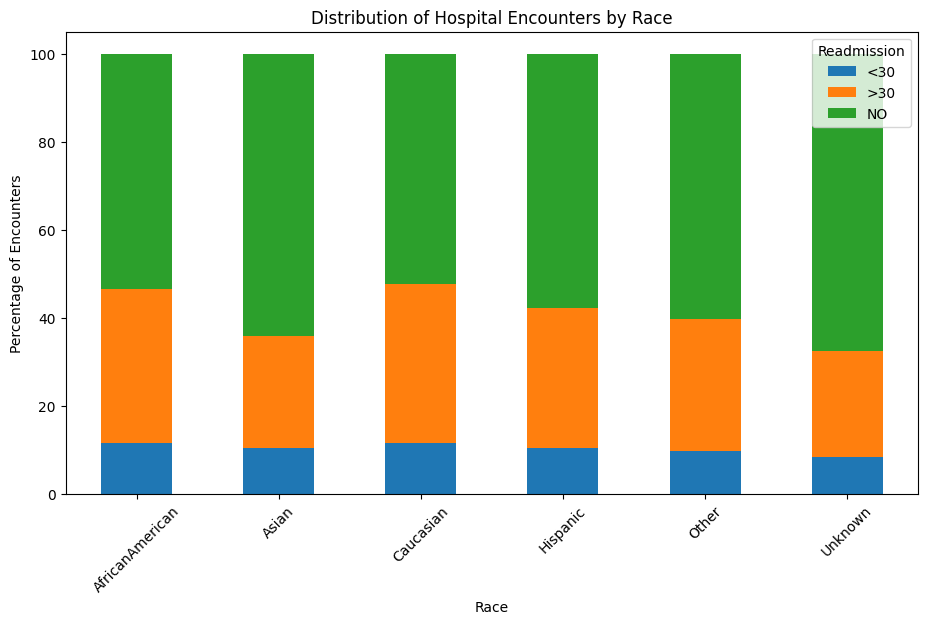

In [ ]:
# Handling the missing race data

# Replace '?' with 'Unknown'
patient_df['race'] = patient_df['race'].replace('?', 'Unknown')


race_readmission = pd.crosstab(
    patient_df['race'],
    patient_df['readmitted'],
    normalize='index'
) * 100


race_readmission.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Readmission Status by Race')
plt.xlabel('Race')
plt.ylabel('Percentage of Encounters')
plt.xticks(rotation=45)
plt.legend(title='Readmission')
plt.title('Distribution of Hospital Encounters by Race')

plt.show()

In [ ]:
## Convert medications to 1 or 0 if prescribed EXCEPT for INSULIN and METFORMIN
## which are the most common medications

medication_cols = [
    'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide',
    'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone'
]

# Add all drugs prescribed and drugs changed
patient_df["n_drugs_prescribed"] = (patient_df[medication_cols] != "No").sum(axis=1)
patient_df["n_drugs_changed"] = patient_df[medication_cols].isin(["Up", "Down"]).sum(axis=1)

# Ensure we only process columns that exist in the dataframe
med_cols_to_convert = [col for col in medication_cols if col in patient_df.columns]

# Map 'Up', 'Down', 'Steady' to 1 and 'No' to 0
for col in med_cols_to_convert:
    patient_df[col] = patient_df[col].replace({
        'Up': 1,
        'Down': 1,
        'Steady': 1,
        'No': 0,
        'NO': 0
    })


/tmp/ipykernel_1562/2827130828.py:23: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  patient_df[col] = patient_df[col].replace({


In [ ]:
patient_df['readmitted_binary'] = patient_df['readmitted'].replace({
    '<30': 1,
    '>30': 1,
    'NO': 0,
    'No': 0
})

print(patient_df['readmitted_binary'].value_counts())

readmitted_binary
0    53212
1    46902
Name: count, dtype: int64


/tmp/ipykernel_1562/695610219.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  patient_df['readmitted_binary'] = patient_df['readmitted'].replace({


In [ ]:
# Apply the multiclass mapping
# <30 is 1, >30 is 2, No/NO is 0
patient_df['readmitted_multiclass'] = patient_df['readmitted'].replace({
    '<30': 1,
    '>30': 2,
    'NO': 0,
    'No': 0
})

print("Value counts for the new multiclass target:")
print(patient_df['readmitted_multiclass'].value_counts(dropna=False))

Value counts for the new multiclass target:
readmitted_multiclass
0    53212
2    35545
1    11357
Name: count, dtype: int64


/tmp/ipykernel_1562/2380948227.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  patient_df['readmitted_multiclass'] = patient_df['readmitted'].replace({


In [ ]:
# Cleaned columns for OneHot Encoding
patient_df['A1Cresult'] = patient_df['A1Cresult'].fillna('NotTested')
patient_df['max_glu_serum'] = patient_df['max_glu_serum'].fillna('NotTested')

In [ ]:
# List of medications to keep as individual columns
meds_to_keep = [
    'insulin', 'metformin', 'glipizide', 'glyburide',
    'pioglitazone', 'rosiglitazone', 'glimepiride', 'repaglinide'
]

# All medication columns list
all_medication_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide',
    'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone'
]

# Find which of the other medications exist in patient_df(excluding the ones to keep)
meds_to_group = [col for col in all_medication_cols if col in patient_df.columns and col not in meds_to_keep]

# Create other_medications column flag (1 if any of the group columns are not 0 / not "No", else 0)
# In previous steps, medications were converted to 1 for prescribed ('Up', 'Down', 'Steady') and 0 for 'No'
other_meds_mask = patient_df[meds_to_group].isin([1, 'Up', 'Down', 'Steady']).any(axis=1)
patient_df['other_medications'] = other_meds_mask.astype(int)

# Drop the grouped medication columns from patient
patient_df = patient_df.drop(columns=meds_to_group)

# Verify changes
print("Columns after medication cleaning:")
updated_med_cols = [col for col in meds_to_keep if col in patient_df.columns] + ['other_medications']
print(patient_df[updated_med_cols].head())
print("\nValue counts for other_medications:")
print(patient_df['other_medications'].value_counts())


Columns after medication cleaning:
  insulin metformin  glipizide  glyburide  pioglitazone  rosiglitazone  \
0      No        No          0          0             0              0   
1      Up        No          0          0             0              0   
2      No        No          1          0             0              0   
3      Up        No          0          0             0              0   
4  Steady        No          1          0             0              0   

   glimepiride  repaglinide  other_medications  
0            0            0                  0  
1            0            0                  0  
2            0            0                  0  
3            0            0                  0  
4            0            0                  0  

Value counts for other_medications:
other_medications
0    98224
1     1890
Name: count, dtype: int64


In [ ]:
# Select categorical columns to encode
categorical_cols = [
    'race', 'gender', 'age', 'admission_type',
    'discharge_disposition', 'admission_source',
    'diag_1_category', 'diag_2_category', 'diag_3_category',
    'insulin', 'metformin', 'change', 'diabetesMed'
]

# Filter only columns that exist in patient_df
existing_cat_cols = [col for col in categorical_cols if col in patient_df.columns]

# Apply One-Hot Encoding using pd.get_dummies
patient_df_encoded = pd.get_dummies(patient_df, columns=existing_cat_cols, drop_first=False)

# Display the shape of the new dataframe and head
print("Original shape:", patient_df.shape)
print("Encoded shape:", patient_df_encoded.shape)
display(patient_df_encoded.head())


Original shape: (100114, 43)
Encoded shape: (100114, 130)


,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,...,insulin_Steady,insulin_Up,metformin_Down,metformin_No,metformin_Steady,metformin_Up,change_Ch,change_No,diabetesMed_No,diabetesMed_Yes
0,2278392,8222157,6,25,1,1,41,0,1,0,...,False,False,False,True,False,False,False,True,True,False
1,149190,55629189,1,1,7,3,59,0,18,0,...,False,True,False,True,False,False,True,False,False,True
2,64410,86047875,1,1,7,2,11,5,13,2,...,False,False,False,True,False,False,False,True,False,True
3,500364,82442376,1,1,7,2,44,1,16,0,...,False,True,False,True,False,False,True,False,False,True
4,16680,42519267,1,1,7,1,51,0,8,0,...,True,False,False,True,False,False,True,False,False,True


In [ ]:
# Combine both sets of columns for encoding
all_cols_to_encode = categorical_cols + medication_cols + ['A1Cresult', 'max_glu_serum', 'other_medications']

# Filter only columns that exist in patient_df
existing_cols_to_encode = [col for col in all_cols_to_encode if col in patient_df.columns]

# Apply One-Hot Encoding
patient_df_encoded = pd.get_dummies(patient_df, columns=existing_cols_to_encode, drop_first=True)

# Display new dimensions and preview
print("Original patient_df shape:", patient_df.shape)
print("Encoded patient_df shape:", patient_df_encoded.shape)
display(patient_df_encoded.head())


Original patient_df shape: (100114, 43)
Encoded patient_df shape: (100114, 121)


,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,...,glyburide_1,pioglitazone_1,rosiglitazone_1,A1Cresult_>8,A1Cresult_Norm,A1Cresult_NotTested,max_glu_serum_>300,max_glu_serum_Norm,max_glu_serum_NotTested,other_medications_1
0,2278392,8222157,6,25,1,1,41,0,1,0,...,False,False,False,False,False,True,False,False,True,False
1,149190,55629189,1,1,7,3,59,0,18,0,...,False,False,False,False,False,True,False,False,True,False
2,64410,86047875,1,1,7,2,11,5,13,2,...,False,False,False,False,False,True,False,False,True,False
3,500364,82442376,1,1,7,2,44,1,16,0,...,False,False,False,False,False,True,False,False,True,False
4,16680,42519267,1,1,7,1,51,0,8,0,...,False,False,False,False,False,True,False,False,True,False


## Data Cleaning Summary

## 1. Cleaned Columns & Rows
*   Removed column that have more than 90% of missing values. -- `weight`
* Removed columns that have more than 50% of missing values and high variety categorical column -- `payer_code`,`medical_specialty`
*   Removed medications column that were not prescribed to any patients -- `citoglipton` & `examide`
* Removed patients that have already expired

## 2. Mapped column IDs to simplified descriptions
*   The initial mapping table has more variety and more specific descriptions for each scenario.
* To simplify this for better processing and understanding of the model, we grouped together similar scenarios into the same categories. (e.g. Multiple variations of a transferred admitted patient will be categorized together as 'Transferred')

## 3. ICD-9 Codes were mapped by their higher/parent category
*  Similarly, we grouped diagnoses together into their parent category.
*  Patients with '?' diagnosis were cleaned with 'Missing'

## 4. Handing `race` column
*  We replaced values of '?' in the `race` column with 'Unknown'
*  In our plot, we see that there is 'Other' and we didn't group this together. This is to remain accuracy. 'Other' could mean that this patient has their race in the data but not in the existing category set.
* In healthcare, it is best not to impute on demographics to avoid false data representation.

## 5. Converted medications column into Binary
* All medications column were converted into integer binary to represent 1 if the patient was prescribed and 0 if not prescribed.
* Added new columns that adds all prescribed medications and another column that adds medications that were changed.

## 6. Removed low impact medications columns
* Low-impact medications were removed that are > 1% of the dataset. Grouped together by a flag 1 if prescribed `other_medications`
* These are the medications included `insulin` `metformin` `glipizide` `glyburide` `pioglitazone` `rosiglitazone` `glimepiride` `repaglinide`


## 7. Converted categorical columns (including medications columns) into One Hot Encoding
* New patient dataframe is created with 110 columns -- `patient_df_encoded`

## 8. Converted readmitted target variable as binary and multiclass for multi model option
* If patient was readmitted within 30 days or after 30 days, the selection is 1; if patient was not readmitted, it is 0. --`readmitted_binary`
* If patient was readmitted within 30 days, it is class 1. If more than 30 days, it is considered class 2. If not readmitted, it is class 0. -- `readmitted_multiclass`



In [ ]:
import pandas as pd
import numpy as np

# Define continuous numerical columns
numeric_cols = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses', 'n_drugs_prescribed', 'n_drugs_changed'
]

# Calculate outliers for each column
for col in numeric_cols:
    Q1 = patient_df[col].quantile(0.25)
    Q3 = patient_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count how many rows fall outside the bounds
    outliers = patient_df[(patient_df[col] < lower_bound) | (patient_df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers ({(len(outliers)/len(patient_df))*100:.1f}%")



time_in_hospital: 2186 outliers (2.2%
num_lab_procedures: 122 outliers (0.1%
num_procedures: 4811 outliers (4.8%
num_medications: 2470 outliers (2.5%
number_outpatient: 16490 outliers (16.5%
number_emergency: 11189 outliers (11.2%
number_inpatient: 6897 outliers (6.9%
number_diagnoses: 278 outliers (0.3%
n_drugs_prescribed: 280 outliers (0.3%
n_drugs_changed: 3950 outliers (3.9%


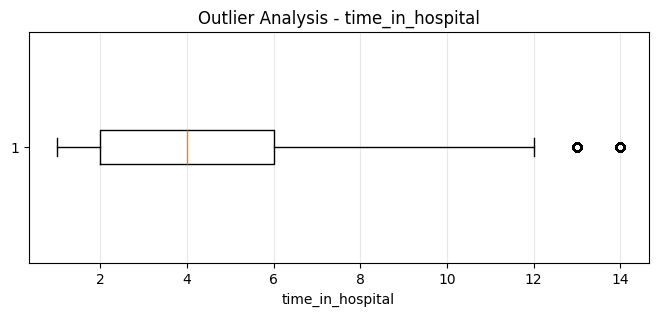

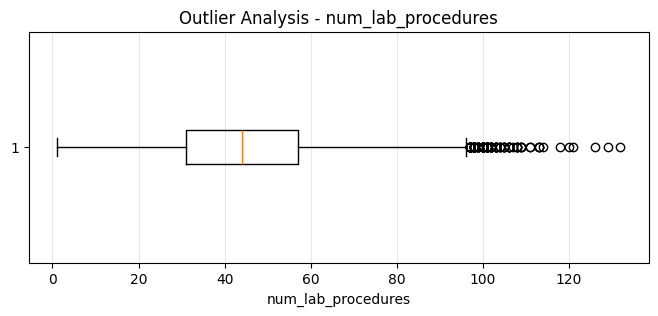

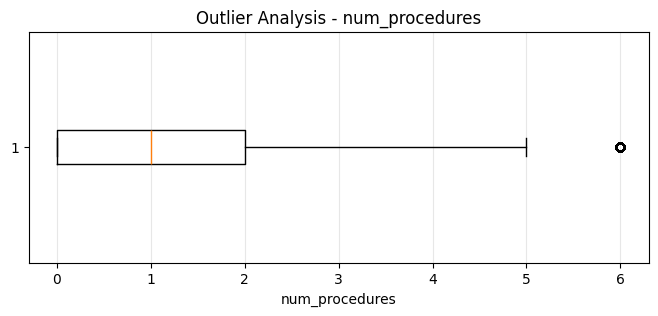

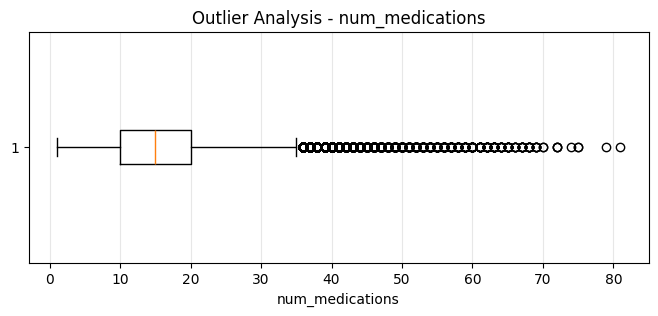

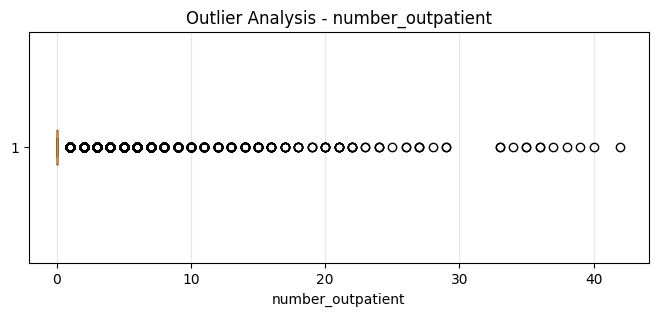

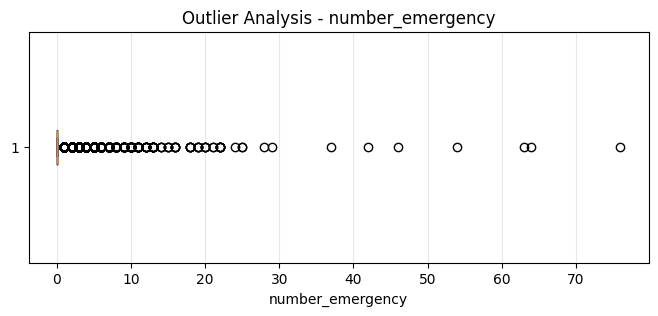

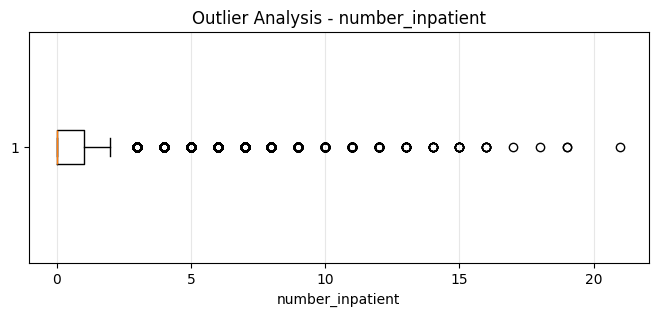

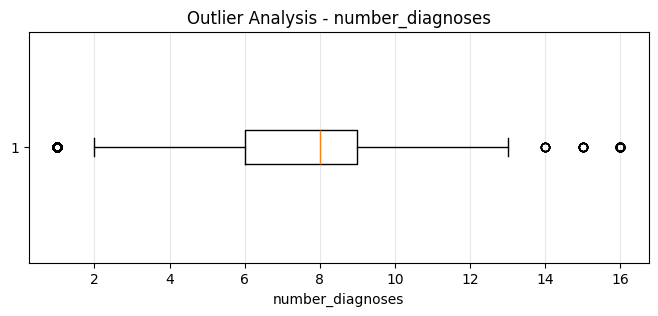

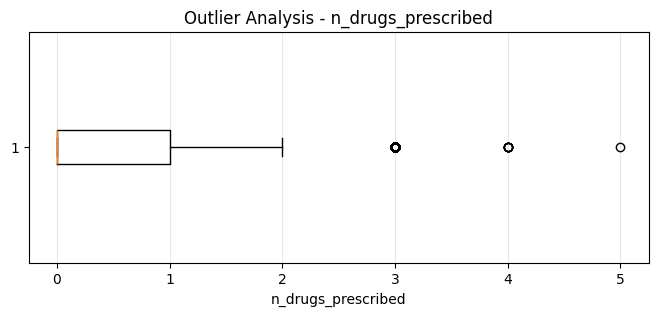

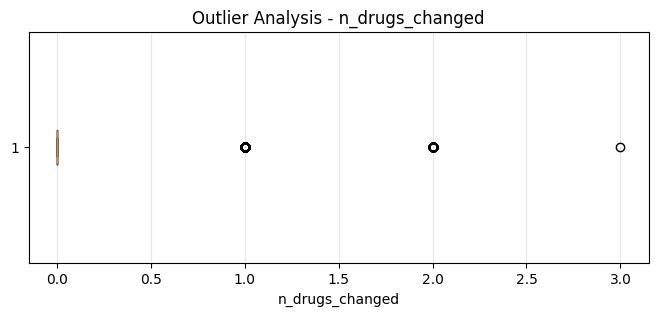

In [ ]:
import matplotlib.pyplot as plt

# Visualize outliers for each numerical feature
for col in numeric_cols:

    plt.figure(figsize=(8, 3))

    plt.boxplot(
        patient_df[col].dropna(),
        vert=False
    )

    plt.title(f"Outlier Analysis - {col}")
    plt.xlabel(col)
    plt.grid(axis="x", alpha=0.3)

    plt.show()

# Outlier Analysis – Summary and Findings

**Methodology:**

Outlier analysis was conducted on eight numerical features in the diabetic hospital readmission dataset using the Interquartile Range (IQR) method and boxplot visualizations. The IQR method was used to identify potential outliers, while boxplots helped visualize the distribution and extreme values of each feature.

Additional verification was performed by examining the minimum and maximum values, negative values, missing values, and five highest observations for each numerical feature.

**Key Findings:**

The analysis identified several potential outliers, particularly in outpatient, emergency, and inpatient visit counts. These features showed right-skewed distributions, with most observations having relatively low values and a smaller number having unusually high values.

The highest observed values included:

- Emergency visits: 76
- Outpatient visits: 42
- Inpatient visits: 21
- Medications: 81
- Laboratory procedures: 132
- Hospital stay duration: 14 days
- Procedures: 6
- Diagnoses: 16

No negative or missing values were identified across all eight numerical features.

Although some observations were unusually high, these values may represent genuine patient histories rather than data-entry errors. In particular, patients requiring frequent hospital visits may have characteristics relevant to predicting 30-day readmission.

**Decision:**

No outliers were removed, replaced, or modified during the analysis. All original observations were retained to preserve potentially important clinical information.

**Recommendations:**

Retain the identified outliers unless further investigation confirms that they are invalid. Unusually high values should be reviewed against the dataset documentation to assess their plausibility.

During model development, the group should evaluate whether extreme values affect model performance. If necessary, appropriate preprocessing techniques may be considered, supported by evidence and model evaluation results.

**Conclusion:**

The outlier analysis identified unusual numerical observations but did not reveal negative or missing values in the eight features examined. Since extreme values may contain useful information about patients' healthcare utilization, retaining them is recommended at this stage.

Further evaluation during model development will help determine whether additional preprocessing is necessary for predicting 30-day hospital readmission.

In [ ]:
for col in numeric_cols:
    values = patient_df[col].dropna()

    print(f"\nFeature: {col}")
    print(f"Minimum value: {values.min()}")
    print(f"Maximum value: {values.max()}")
    print(f"Negative values: {(values < 0).sum()}")
    print(f"Missing values: {patient_df[col].isna().sum()}")
    print("Top 5 highest values:")
    print(values.nlargest(5).tolist())


Feature: time_in_hospital
Minimum value: 1
Maximum value: 14
Negative values: 0
Missing values: 0
Top 5 highest values:
[14, 14, 14, 14, 14]

Feature: num_lab_procedures
Minimum value: 1
Maximum value: 132
Negative values: 0
Missing values: 0
Top 5 highest values:
[132, 129, 126, 121, 120]

Feature: num_procedures
Minimum value: 0
Maximum value: 6
Negative values: 0
Missing values: 0
Top 5 highest values:
[6, 6, 6, 6, 6]

Feature: num_medications
Minimum value: 1
Maximum value: 81
Negative values: 0
Missing values: 0
Top 5 highest values:
[81, 79, 75, 75, 74]

Feature: number_outpatient
Minimum value: 0
Maximum value: 42
Negative values: 0
Missing values: 0
Top 5 highest values:
[42, 40, 39, 38, 37]

Feature: number_emergency
Minimum value: 0
Maximum value: 76
Negative values: 0
Missing values: 0
Top 5 highest values:
[76, 64, 63, 54, 46]

Feature: number_inpatient
Minimum value: 0
Maximum value: 21
Negative values: 0
Missing values: 0
Top 5 highest values:
[21, 19, 19, 18, 17]

Featu

I did not find any negative or missing values across all eight numerical features. However, some values were unusually high, including 76 emergency visits, 42 outpatient visits, and 81 medications.

# Correlation Analysis - Binary Classification

In [ ]:
analysis_df = patient_df.copy()

# Validate the target before converting it.
valid_labels = ['<30', '>30', 'NO']

if not analysis_df['readmitted'].isin(valid_labels).all():
    raise ValueError("Check missing or unexpected readmission labels.")

# Include both '<30' and '>30' as 1, and 'NO' as 0
analysis_df['readmitted_30'] = analysis_df['readmitted'].isin(['<30', '>30']).astype(int)

print("Encounters retained:", len(analysis_df))

display(
    analysis_df['readmitted_30']
    .value_counts()
    .rename_axis('Readmitted_1')
    .to_frame('Count')
)

Encounters retained: 100114


,Count
Readmitted_1,
0,53212
1,46902


In [ ]:
corr_data = analysis_df[numeric_cols + ['readmitted_30']]

pearson_corr = corr_data.corr(method='pearson')
spearman_corr = corr_data.corr(method='spearman')

target_correlations = pd.DataFrame({
    'Pearson': pearson_corr.loc[numeric_cols, 'readmitted_30'],
    'Spearman': spearman_corr.loc[numeric_cols, 'readmitted_30']
})

target_correlations['Absolute_Pearson'] = (
    target_correlations['Pearson'].abs()
)

target_correlations = target_correlations.sort_values(
    'Absolute_Pearson',
    ascending=False
)

display(target_correlations.round(4))

,Pearson,Spearman,Absolute_Pearson
number_inpatient,0.2228,0.2362,0.2228
number_diagnoses,0.1205,0.1171,0.1205
number_emergency,0.1035,0.1286,0.1035
number_outpatient,0.0836,0.1116,0.0836
time_in_hospital,0.0543,0.0627,0.0543
num_medications,0.0523,0.0759,0.0523
num_lab_procedures,0.0473,0.0486,0.0473
num_procedures,-0.0406,-0.0424,0.0406
n_drugs_prescribed,0.0199,0.0203,0.0199
n_drugs_changed,0.0048,0.0046,0.0048


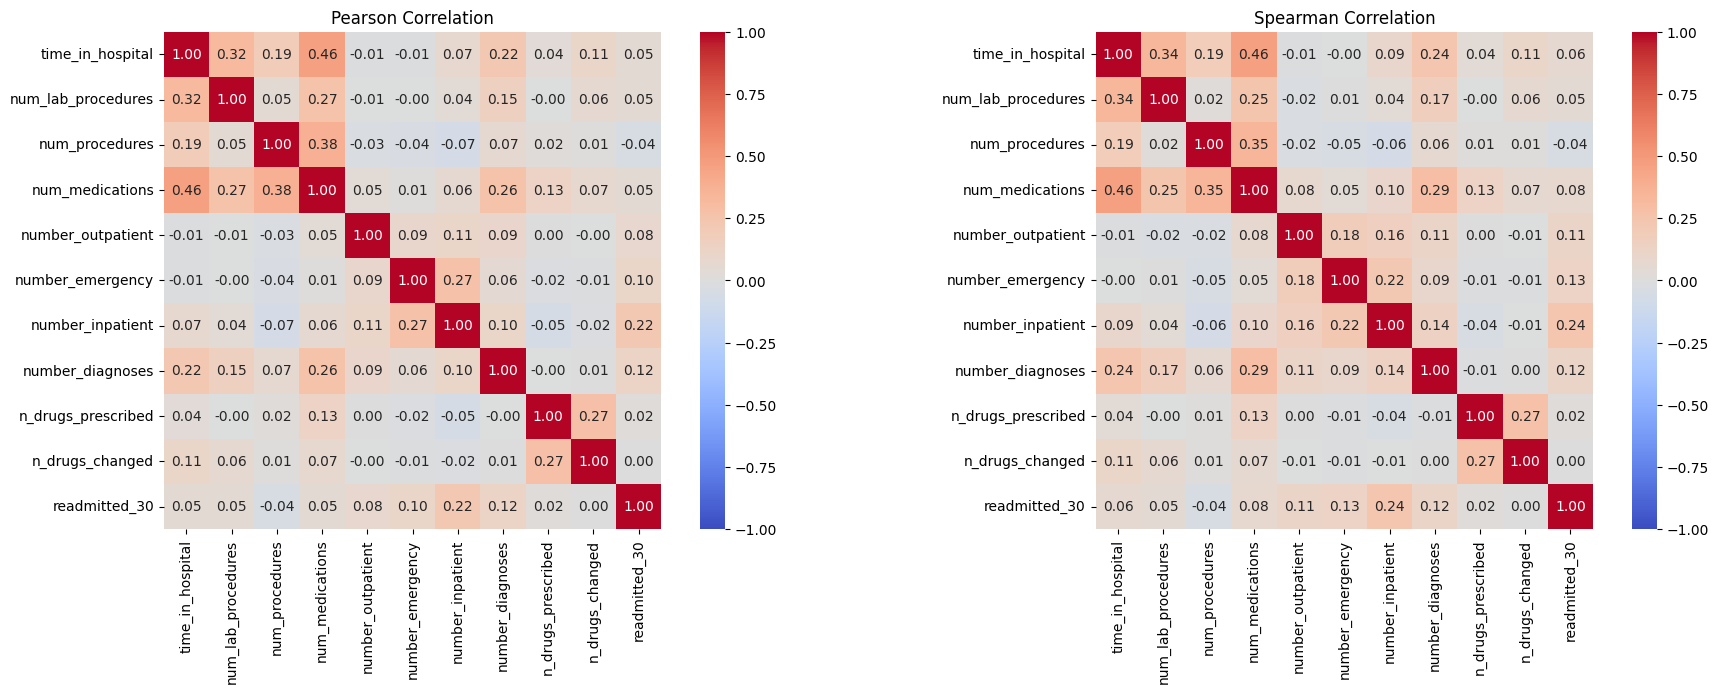

In [ ]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

for ax, matrix, title in [
    (axes[0], pearson_corr, 'Pearson Correlation'),
    (axes[1], spearman_corr, 'Spearman Correlation')
]:
    sns.heatmap(
        matrix,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [ ]:
feature_corr = analysis_df[numeric_cols].corr(method='spearman')

upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape, dtype=bool),
        k=1
    )
)

pairs = upper_triangle.stack().rename('Spearman').reset_index()
pairs.columns = ['Feature_1', 'Feature_2', 'Spearman']

pairs['Absolute_Correlation'] = pairs['Spearman'].abs()

high_corr_pairs = pairs[
    pairs['Absolute_Correlation'] >= 0.80
].sort_values('Absolute_Correlation', ascending=False)

display(high_corr_pairs.round(4))

if high_corr_pairs.empty:
    print("No numerical feature pairs meet the review threshold of 0.80.")

,Feature_1,Feature_2,Spearman,Absolute_Correlation


No numerical feature pairs meet the review threshold of 0.80.


In [ ]:
categorical_cols = [
    'age',
    'race',
    'gender',
    'admission_type',
    'discharge_disposition',
    'admission_source',
    'diag_1_category',
    'diag_2_category',
    'diag_3_category',
    'max_glu_serum',
    'A1Cresult',
    'insulin',
    'metformin',
    'change',
    'diabetesMed'
]

for col in categorical_cols:
    if col not in analysis_df.columns:
        continue

    category = (
        analysis_df[col]
        .astype('string')
        .fillna('Missing / verify original coding')
    )

    summary = (
        analysis_df
        .assign(Category=category)
        .groupby('Category')['readmitted_30']
        .agg(Encounters='size', Readmissions_30='sum',
             Readmission_Rate='mean')
    )

    summary['Readmission_Rate_Percent'] = (
        summary.pop('Readmission_Rate') * 100
    )

    print(f"\n{col}")
    display(
        summary.sort_values(
            'Readmission_Rate_Percent',
            ascending=False
        ).round(2)
    )


age


,Encounters,Readmissions_30,Readmission_Rate_Percent
Category,,,
[80-90),16706,8301,49.69
[70-80),25562,12544,49.07
[60-70),22185,10399,46.87
[20-30),1650,746,45.21
[40-50),9626,4305,44.72
[50-60),17102,7585,44.35
[30-40),3765,1611,42.79
[90-100),2668,1118,41.90
[10-20),690,264,38.26



race


,Encounters,Readmissions_30,Readmission_Rate_Percent
Category,,,
Caucasian,74845,35716,47.72
AfricanAmerican,18888,8789,46.53
Hispanic,2024,854,42.19
Other,1486,591,39.77
Asian,632,226,35.76
Unknown,2239,726,32.43



gender


,Encounters,Readmissions_30,Readmission_Rate_Percent
Category,,,
Female,53861,25670,47.66
Male,46250,21232,45.91
Unknown/Invalid,3,0,0.00


... (20 outputs left out)


change


,Encounters,Readmissions_30,Readmission_Rate_Percent
Category,,,
Ch,46443,22830,49.16
No,53671,24072,44.85



diabetesMed


,Encounters,Readmissions_30,Readmission_Rate_Percent
Category,,,
Yes,77272,37429,48.44
No,22842,9473,41.47


/tmp/ipykernel_1562/2013700617.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  med_corr_df[col] = med_corr_df[col].replace({
/tmp/ipykernel_1562/2013700617.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  med_corr_df[col] = med_corr_df[col].replace({


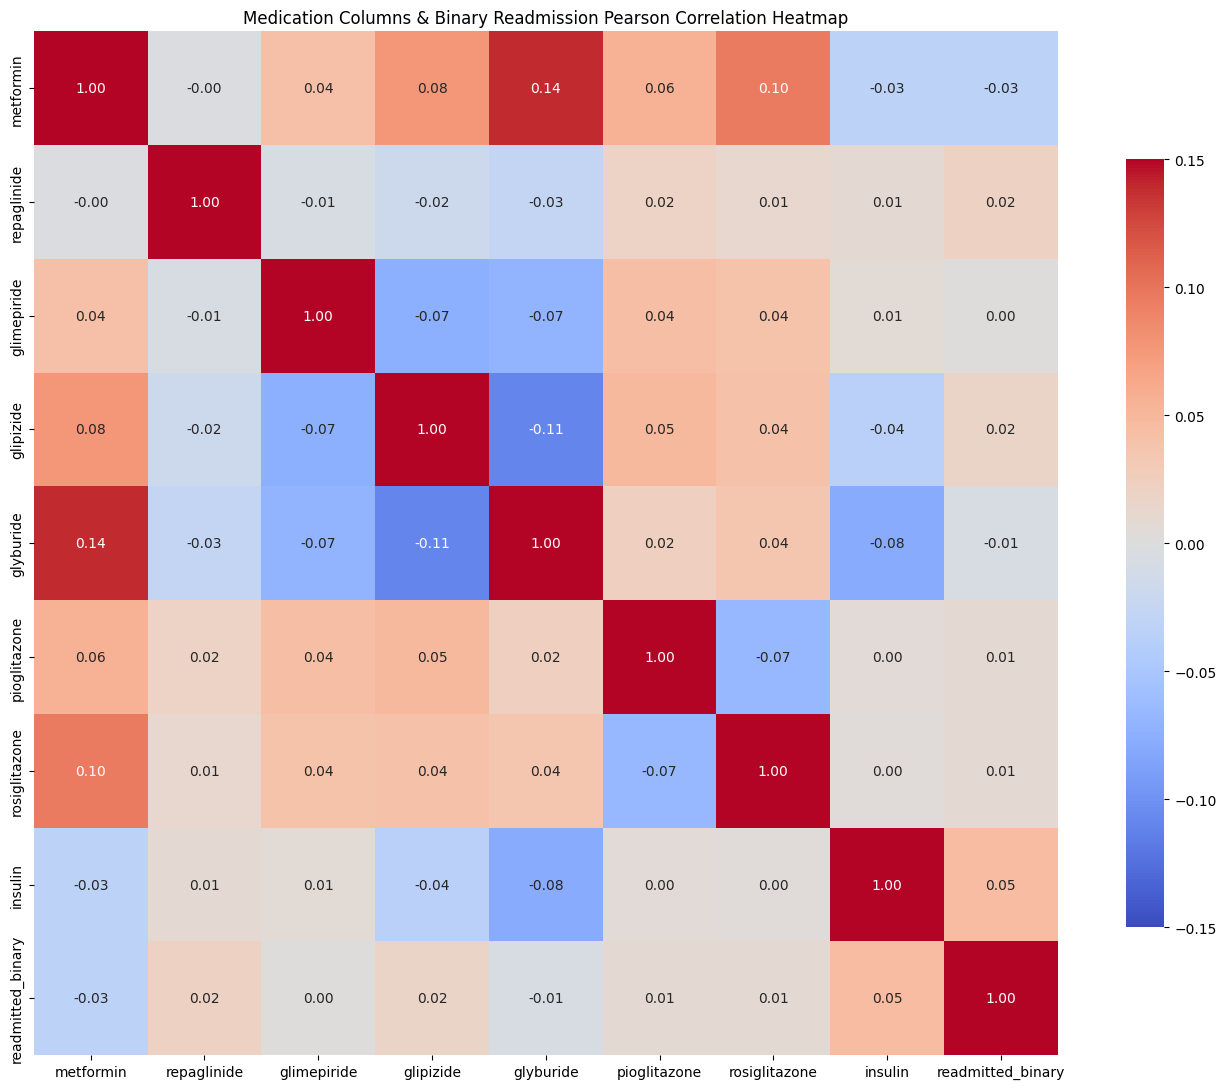

In [ ]:
# List of medication columns
medication_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide',
    'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone'
]

# Ensure we only use medication columns that exist in patient_df
existing_meds = [col for col in medication_cols if col in patient_df.columns]

# Prepare data with target
med_corr_df = patient_df[existing_meds].copy()
med_corr_df['readmitted_binary'] = patient_df['readmitted_binary']

# Map medication columns to numeric (1 if prescribed, 0 if not prescribed) to prevent string to float ValueError
for col in existing_meds:
    med_corr_df[col] = med_corr_df[col].replace({
        'Up': 1,
        'Down': 1,
        'Steady': 1,
        'No': 0,
        'NO': 0
    }).astype(float)

# Calculate Pearson correlation matrix
corr_matrix = med_corr_df.corr(method='pearson')

# Focus specifically on correlations of medications with each other and with readmitted_binary
plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.15,
    vmax=0.15,
    center=0,
    square=True,
    cbar_kws={'shrink': 0.75}
)
plt.title('Medication Columns & Binary Readmission Pearson Correlation Heatmap')
plt.tight_layout()
plt.show()

## Summary - Correlation Analysis and Categorical Associations

### 1. Purpose and Method

This analysis explored how patient and hospital encounter characteristics relate to readmission, specifically incorporating medication columns and their associations.

The target variable was converted into two categories:

- **1:** Readmitted (`<30` or `>30`).
- **0:** No recorded readmission (`NO`).

Pearson and Spearman correlations were calculated for eight numerical features. Pearson measured linear relationships, while Spearman examined relationships using ranked values.

For the medication columns, Pearson correlation coefficients were calculated to understand both how individual medications correlate with the binary readmission target and how medications associate with each other (representing co-prescription patterns).

### 2. Readmission Distribution

The cleaned dataset contains **100,114 hospital encounters**.

| Readmission Outcome | Encounters | Percentage |
|---|---:|---:|
| Readmitted (`readmitted_binary = 1`) | 46,902 | 46.85% |
| No readmission (`readmitted_binary = 0`) | 53,212 | 53.15% |

With this binary definition, the classes are nearly balanced, offering an ideal target distribution for modeling without severe imbalance issues.

### 3. Numerical Correlation Findings

| Numerical Feature | Pearson | Spearman |
|---|---:|---:|
| Previous inpatient visits (`number_inpatient`) | 0.2228 | 0.2362 |
| Number of diagnoses (`number_diagnoses`) | 0.1205 | 0.1171 |
| Previous emergency visits (`number_emergency`) | 0.1035 | 0.1286 |
| Previous outpatient visits (`number_outpatient`) | 0.0836 | 0.1116 |
| Time in hospital | 0.0543 | 0.0627 |
| Number of medications | 0.0523 | 0.0759 |
| Number of laboratory procedures | 0.0473 | 0.0486 |
| Number of procedures | -0.0406 | -0.0424 |

**Previous inpatient visits had the strongest association with readmission**, followed by the number of diagnoses and previous emergency visits. These features represent key clinical indicators of overall healthcare utilization and complexity.

### 4. Medication Correlation Findings

* **Weak Direct Correlation with Target:** Individual diabetes medications exhibit exceptionally weak linear correlations with the target variable `readmitted_binary` (all coefficients fall between $-0.03$ and $+0.05$). Specifically:
  * `insulin` has a tiny positive correlation ($+0.05$).
  * `metformin` has a tiny negative correlation ($-0.03$).

### 5. Relationships Between Numerical Features

No numerical feature pair reached the selected absolute Spearman correlation threshold of **0.80**. The strongest relationship remained between **time in hospital and number of medications** (approx. **0.46**).

### 6. Categorical Findings

#### Age
Older patient cohorts make up the majority of encounters (the `[70-80)` age group is the largest). Readmission rates do not follow a simple linear path with age, highlighting the need to preserve age as a discrete categorical feature.

#### Gender
Female and male encounters exhibit highly similar readmission behaviors (around ~47% readmission overall), showing very little baseline predictive difference.

#### Discharge Disposition
Discharge categories show notable differences in outcomes, where transfers and non-home discharges generally experience higher relative readmission rates compared to those discharged home.

#### Diagnosis Groups
Different clinical primary and secondary diagnosis codes map to varying readmission risks, illustrating that secondary diagnoses contribute valuable clinical signal.

# Multiclass - Correlation Analysis

Readmission class distribution:


,Encounters,Percent
readmitted,,
NO,53212,53.15
<30,11357,11.34
>30,35545,35.5


Top 20 feature associations across the three classes:


,r_NO,r_<30,r_>30,max_abs_r
number_inpatient,-0.2228,0.1676,0.1212,0.2228
number_diagnoses,-0.1205,0.0523,0.0910,0.1205
number_emergency,-0.1035,0.0608,0.0677,0.1035
number_outpatient,-0.0836,0.0191,0.0745,0.0836
admission_source_Transferred,0.0809,-0.0105,-0.0774,0.0809
discharge_disposition_Transferred to Other Care,-0.0324,0.0766,-0.0170,0.0766
discharge_disposition_Hospice,0.0630,-0.0160,-0.0551,0.0630
diabetesMed_Yes,-0.0586,0.0259,0.0439,0.0586
time_in_hospital,-0.0543,0.0455,0.0264,0.0543
num_medications,-0.0523,0.0407,0.0276,0.0523


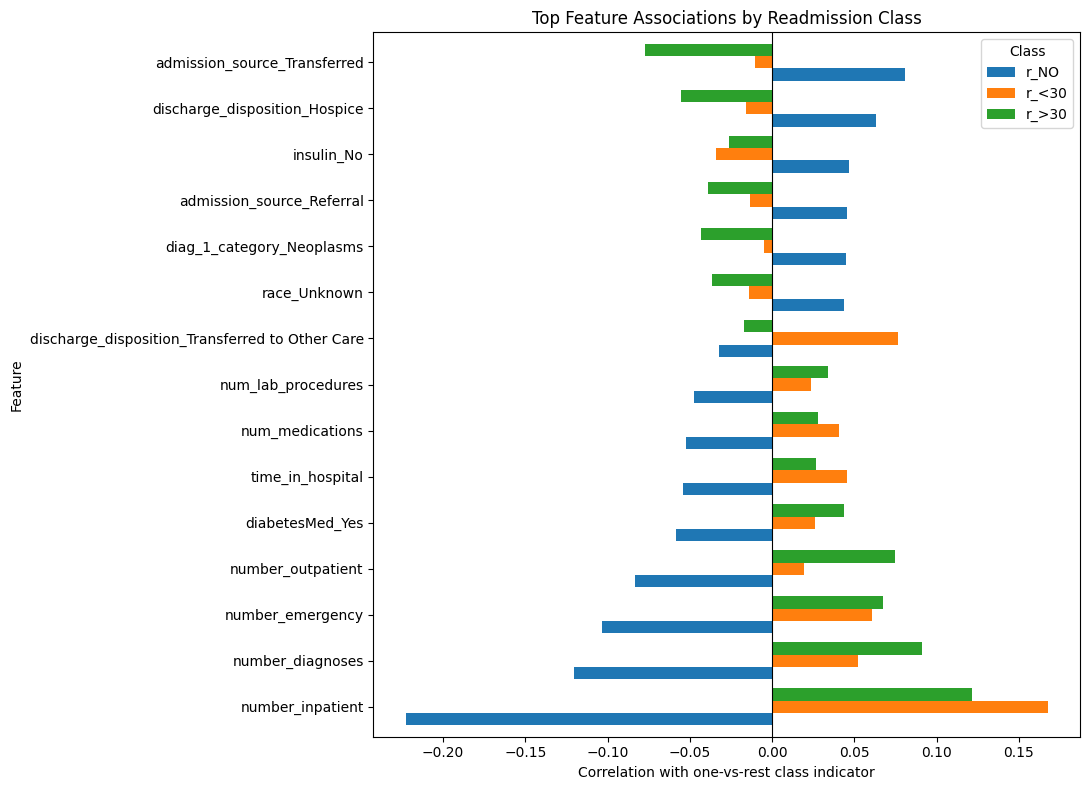

Feature pairs with absolute correlation >= 0.80:


,Feature_1,Feature_2,Correlation,Absolute_Correlation
5842,metformin_No,metformin_Steady,-0.948,0.948


In [ ]:
# Remove IDs, raw codes, and target columns from the predictors
drop_cols = [
    "encounter_id", "patient_nbr",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "diag_1", "diag_2", "diag_3",
    "readmitted", "readmitted_binary", "readmitted_multiclass",
    "readmitted_30", "target_30"
]

corr_features = patient_df_encoded.drop(
    columns=drop_cols, errors="ignore"
).copy()

# One-hot encode any categorical columns still present
categorical_cols = corr_features.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_cols:
    corr_features[col] = (
        corr_features[col]
        .astype("string")
        .fillna("Missing / not recorded")
        .replace("?", "Unknown / not recorded")
    )

corr_features = pd.get_dummies(
    corr_features,
    columns=categorical_cols,
    drop_first=False,
    dtype="int8"
)

# Keep numeric predictors and make sure the two derived counts are included
corr_features = corr_features.select_dtypes(
    include=["number", "bool"]
).astype(float)

derived_cols = ["n_drugs_prescribed", "n_drugs_changed"]
missing_derived = [col for col in derived_cols if col not in corr_features.columns]
if missing_derived:
    raise ValueError(f"Missing derived columns: {missing_derived}")

# Remove constant features
corr_features = corr_features.loc[
    :, corr_features.nunique(dropna=True) > 1
]

# Use the original three target labels
target = (
    patient_df_encoded["readmitted"]
    .astype("string")
    .str.strip()
    .replace({"No": "NO", "no": "NO"})
)

class_order = ["NO", "<30", ">30"]
unexpected_labels = sorted(set(target.dropna().unique()) - set(class_order))

if unexpected_labels:
    raise ValueError(f"Unexpected readmission labels: {unexpected_labels}")
if target.isna().any():
    raise ValueError("The readmitted target contains missing values.")
if not corr_features.index.equals(target.index):
    raise ValueError("Feature rows and target rows are not aligned.")

# Show the number and percentage of encounters in each class
class_counts = target.value_counts().reindex(class_order, fill_value=0)
class_summary = pd.DataFrame({
    "Encounters": class_counts,
    "Percent": (class_counts / len(target) * 100).round(2)
})

print("Readmission class distribution:")
display(class_summary)

# Correlate each feature with one class versus the other two
class_correlations = pd.DataFrame(index=corr_features.columns)

for label in class_order:
    class_indicator = target.eq(label).astype("int8")
    class_correlations[f"r_{label}"] = corr_features.apply(
        lambda feature: feature.corr(class_indicator)
    )

class_correlations["max_abs_r"] = class_correlations[
    [f"r_{label}" for label in class_order]
].abs().max(axis=1)

class_correlations = class_correlations.sort_values(
    "max_abs_r", ascending=False
)

print("Top 20 feature associations across the three classes:")
display(class_correlations.head(20).round(4))

# Plot the 15 strongest associations
top_features = class_correlations.head(15).index
plot_data = class_correlations.loc[
    top_features, [f"r_{label}" for label in class_order]
].sort_values("r_NO")

plot_data.plot(kind="barh", figsize=(11, 8), width=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with one-vs-rest class indicator")
plt.ylabel("Feature")
plt.title("Top Feature Associations by Readmission Class")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

# Check feature pairs for high correlation
feature_corr = corr_features.corr(method="pearson")
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)
)

high_corr_pairs = upper_triangle.stack().rename("Correlation").reset_index()
high_corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]
high_corr_pairs["Absolute_Correlation"] = high_corr_pairs["Correlation"].abs()
high_corr_pairs = (
    high_corr_pairs[high_corr_pairs["Absolute_Correlation"] >= 0.80]
    .sort_values("Absolute_Correlation", ascending=False)
)

print("Feature pairs with absolute correlation >= 0.80:")
display(high_corr_pairs.round(3))

/tmp/ipykernel_1562/965189324.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  med_multiclass_df[col] = med_multiclass_df[col].replace({
/tmp/ipykernel_1562/965189324.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  med_multiclass_df[col] = med_multiclass_df[col].replace({


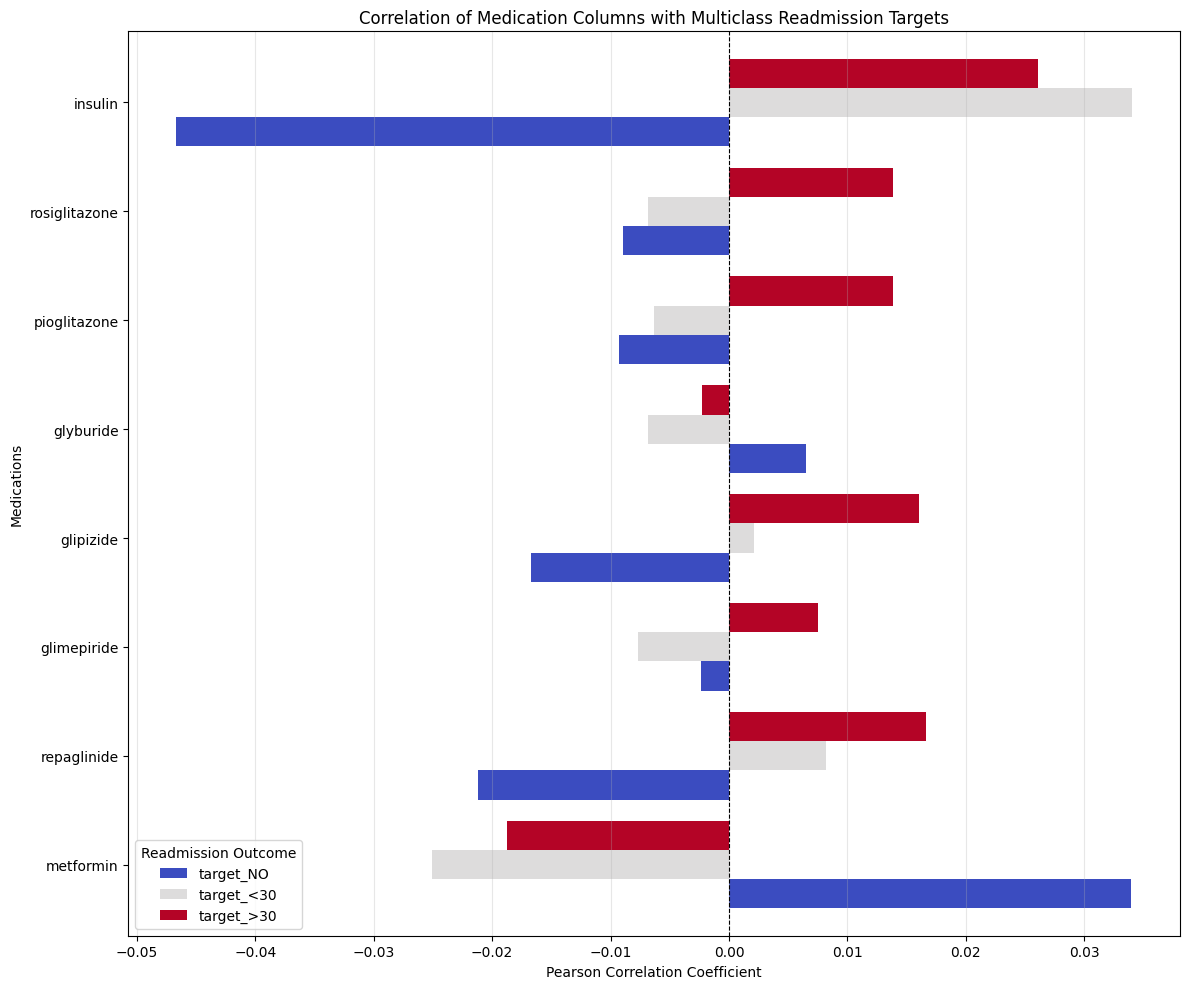

,target_NO,target_<30,target_>30
metformin,0.0340,-0.0251,-0.0188
repaglinide,-0.0212,0.0082,0.0167
glimepiride,-0.0023,-0.0077,0.0075
glipizide,-0.0167,0.0021,0.0160
glyburide,0.0065,-0.0068,-0.0023
pioglitazone,-0.0092,-0.0063,0.0138
rosiglitazone,-0.0090,-0.0069,0.0139
insulin,-0.0467,0.0341,0.0261


In [ ]:
# Build indicator variables for multiclass target ('NO', '<30', '>30')
class_labels = ['NO', '<30', '>30']
med_multiclass_df = patient_df[existing_meds].copy()

for label in class_labels:
    med_multiclass_df[f'target_{label}'] = patient_df['readmitted'].eq(label).astype('int8')

# Map medication columns to numeric (1 if prescribed, 0 if not prescribed) to prevent string to float ValueError
for col in existing_meds:
    med_multiclass_df[col] = med_multiclass_df[col].replace({
        'Up': 1,
        'Down': 1,
        'Steady': 1,
        'No': 0,
        'NO': 0
    }).astype(float)

# Calculate Pearson correlation matrix
corr_matrix = med_multiclass_df.corr(method='pearson')

target_cols = [f'target_{label}' for label in class_labels]
med_target_corr = corr_matrix.loc[existing_meds, target_cols]

plt.figure(figsize=(12, 10))
med_target_corr.plot(kind='barh', ax=plt.gca(), width=0.8, colormap='coolwarm')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Medications')
plt.title('Correlation of Medication Columns with Multiclass Readmission Targets')
plt.legend(title='Readmission Outcome')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(med_target_corr.round(4))

## Multiclass Correlation Analysis

### Method

The original `readmitted` target was analyzed as three separate outcomes: `NO`, `<30`, and `>30`. For each outcome, a one-vs-rest indicator was created: the selected class was coded as 1 and the other two classes as 0. Pearson correlations were calculated between these indicators and the numeric or one-hot encoded features.

The analysis included the eight existing numeric features and the engineered features `n_drugs_prescribed` and `n_drugs_changed`. Identifiers, raw diagnosis codes, and target-derived columns were excluded from the feature set.

### Readmission class distribution

| Outcome | Encounters | Percentage |
|---|---:|---:|
| `NO` | 53,212 | 53.15% |
| `<30` | 11,357 | 11.34% |
| `>30` | 35,545 | 35.50% |

### Main associations

For `NO`, the strongest associations were previous inpatient visits (−0.2228), number of diagnoses (−0.1205), and previous emergency visits (−0.1035).

For `<30`, the strongest associations were previous inpatient visits (0.1676), discharge disposition of transferred to other care (0.0766), and previous emergency visits (0.0608).

For `>30`, the strongest associations were previous inpatient visits (0.1212), number of diagnoses (0.0910), and previous outpatient visits (0.0745).

The engineered feature `n_drugs_changed` had a smaller association with the classes: −0.0587 for `NO`, 0.0351 for `<30`, and 0.0380 for `>30`. `n_drugs_prescribed` was not among the 20 features with the strongest associations.

### Medication Associations

Looking specifically at how diabetes medications relate to the three readmission outcomes:
- **Insulin** exhibits the strongest target associations overall, showing a negative correlation with no readmission (`target_NO` ≈ -0.0467), a positive correlation with early readmission (`target_<30` ≈ 0.0341), and a positive correlation with late readmission (`target_>30` ≈ 0.0261).
- **Metformin** acts protectively, with a positive correlation with no readmission (`target_NO` ≈ 0.0340), a negative correlation with early readmission (`target_<30` ≈ -0.0251), and a negative correlation with late readmission (`target_>30` ≈ -0.0188).
- **Other Medications** (such as glipizide, pioglitazone, repaglinide, and glimepiride) have exceptionally weak linear associations, with most coefficients sitting near or below 0.01.

### Feature-to-feature correlations

No feature pairs had an absolute Pearson correlation of 0.80 or higher in this analysis.

### Interpretation

The largest class associations were with previous inpatient visits, but the correlations are still modest. These results describe associations in this dataset; they do not show that a feature causes readmission or establish that a feature should be removed. In particular, a lower correlation alone is not enough to conclude that a feature is unhelpful for a model.

# FAMD - Dimensionality Reduction

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              2.896         2.81%                      2.81%
1              2.455         2.38%                      5.19%
2              2.382         2.31%                      7.51%
3              2.274         2.21%                      9.71%
4              1.744         1.69%                     11.41%
5              1.643         1.60%                     13.00%
6              1.506         1.46%                     14.47%
7              1.420         1.38%                     15.84%
8              1.361         1.32%                     17.17%
9              1.345         1.31%                     18.47%


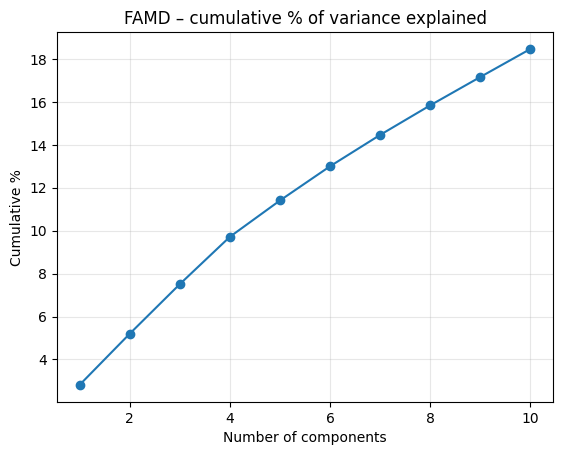


Component 0 – top contributors:
variable
num_medications     0.149
diabetesMed_No      0.091
time_in_hospital    0.089
change_Ch           0.086
change_No           0.074
Name: 0, dtype: float64

Component 1 – top contributors:
variable
diag_1_category_Diabetes    0.080
num_procedures              0.073
admission_type_Elective     0.052
A1Cresult_>8                0.044
diag_3_category_Missing     0.043
Name: 1, dtype: float64

Component 2 – top contributors:
variable
number_diagnoses                   0.103
admission_type_Elective            0.076
num_lab_procedures                 0.069
admission_source_Referral          0.066
admission_source_Emergency Room    0.055
Name: 2, dtype: float64


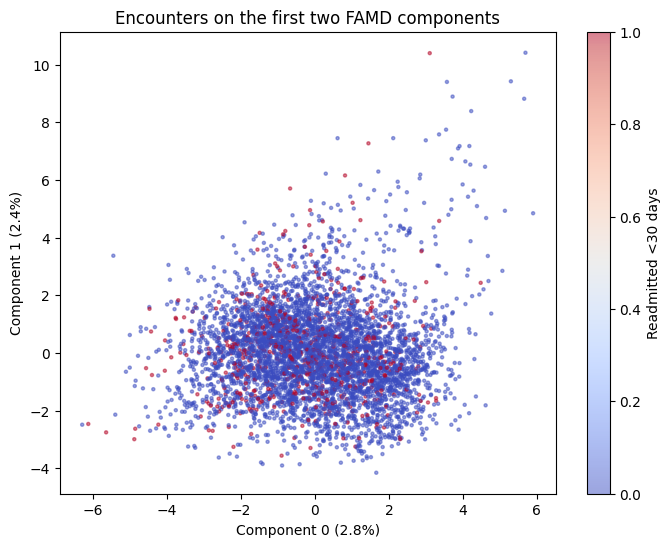

In [ ]:
!pip install -q prince
import prince

categorical_cols = [
    'age',
    'race',
    'gender',
    'admission_type',
    'discharge_disposition',
    'admission_source',
    'diag_1_category',
    'diag_2_category',
    'diag_3_category',
    'max_glu_serum',
    'A1Cresult',
    'insulin',
    'metformin',
    'change',
    'diabetesMed'
]

famd_df = patient_df[numeric_cols + categorical_cols].copy()
famd_df[numeric_cols] = famd_df[numeric_cols].astype(float)
famd_df[categorical_cols] = famd_df[categorical_cols].astype(str)  # FAMD needs text categories

famd = prince.FAMD(n_components=10)
famd.fit(famd_df)

# 1. How much information each component keeps
print(famd.eigenvalues_summary)

var = famd.percentage_of_variance_
plt.plot(range(1, len(var) + 1), var.cumsum(), marker='o')
plt.title('FAMD – cumulative % of variance explained')
plt.xlabel('Number of components'); plt.ylabel('Cumulative %')
plt.grid(alpha=0.3); plt.show()

# 2. Which original variables drive each component (top 5 per component)
contrib = famd.column_contributions_
for comp in contrib.columns[:3]:
    print(f"\nComponent {comp} – top contributors:")
    print(contrib[comp].sort_values(ascending=False).head(5).round(3))

# 3. Do the first two components separate early readmissions?
coords = famd.row_coordinates(famd_df)
target = (patient_df['readmitted'] == '<30').astype(int).values
sample = coords.sample(5000).index
plt.figure(figsize=(8, 6))
plt.scatter(coords.loc[sample, 0], coords.loc[sample, 1],
            c=target[sample], cmap='coolwarm', s=5, alpha=0.5)
plt.colorbar(label='Readmitted <30 days')
plt.xlabel(f'Component 0 ({var[0]:.1f}%)'); plt.ylabel(f'Component 1 ({var[1]:.1f}%)')
plt.title('Encounters on the first two FAMD components')
plt.show()

## Dimensionality Reduction – FAMD

### 1. Purpose and Method
Dimensionality reduction was explored to understand whether the dataset could be summarised by a smaller number of underlying dimensions.

**Factor Analysis of Mixed Data (FAMD)** was selected because the dataset contains both numerical and categorical features. Principal Component Analysis (PCA) only handles numerical variables, while Multiple Correspondence Analysis (MCA) only handles categorical variables. FAMD combines both approaches: numerical variables are standardised and categorical variables are weighted by category frequency, so no single variable type dominates the components.

The analysis included:
- **8 numerical features:** time in hospital, number of lab procedures, procedures, medications, outpatient visits, emergency visits, inpatient visits and diagnoses.
- **13 categorical features:** race, gender, age, admission type, discharge disposition, admission source, the three diagnosis categories, insulin, metformin, change and diabetesMed.

The first 10 components were extracted from the cleaned encounters.

### 2. Variance Explained
| Component | Eigenvalue | % of Variance | Cumulative % |
|---|---|---|---|
| 0 | 2.892 | 2.81% | 2.81% |
| 1 | 2.461 | 2.39% | 5.20% |
| 2 | 2.373 | 2.30% | 7.50% |
| 3 | 2.275 | 2.21% | 9.71% |
| 4 | 1.688 | 1.64% | 11.35% |
| 5 | 1.623 | 1.58% | 12.92% |
| 6 | 1.570 | 1.52% | 14.45% |
| 7 | 1.452 | 1.41% | 15.86% |
| 8 | 1.355 | 1.32% | 17.17% |
| 9 | 1.338 | 1.30% | 18.47% |

The first 10 components together explained only **18.47%** of the total variance, and no single component explained more than 2.81%. The variance is spread across many dimensions, so the dataset cannot be compressed into a few components without losing most of its information.

This is partly due to the large number of categorical levels (for example, 16 diagnosis categories in each of the three diagnosis columns). In FAMD, each additional category adds to the total variance, so the share captured by each component becomes smaller.

### 3. Interpretation of the First Three Components
- **Component 0 – Clinical and medication complexity:** mainly driven by `num_medications` (0.148), `diabetesMed_No` (0.093), `change_Ch` (0.086), `time_in_hospital` (0.086), and `change_No` (0.075). High values represent longer, more complex hospital stays paired with medication adjustments.
- **Component 1 – Diagnosis and procedure profile:** mainly driven by `diag_1_category_Diabetes` (0.073), `num_procedures` (0.072), `admission_type_Elective` (0.049), `A1Cresult_>8` (0.047), and `diag_3_category_Missing` (0.043).
- **Component 2 – Clinical severity and admission pathway:** mainly driven by `number_diagnoses` (0.099), `admission_type_Elective` (0.088), `admission_source_Referral` (0.073), `num_lab_procedures` (0.071), and `admission_source_Emergency Room` (0.059).

These components are clinically meaningful, which suggests the data has a sensible underlying structure.

### 4. Relationship with 30-Day Readmission
A scatter plot of a 5,000-encounter random sample on the first two components showed no clear separation between encounters readmitted within 30 days and other encounters. The two groups overlap heavily.

This is consistent with the correlation analysis, where individual features had only weak associations with early readmission.

### 5. Decisions and Limitations
- FAMD is retained as an **exploratory tool** for understanding the structure of the data, not as a preprocessing step for modelling at this stage.
- Because 10 components explain less than 19% of the variance, replacing the original features with components would discard most of the information. **Feature selection** on the original features is likely more appropriate for the modelling phase.
- Components are linear combinations of features, so they are harder to interpret clinically than the original variables. This matters in a healthcare setting, where model explainability is important.
- FAMD is unsupervised: it finds directions of maximum variance, not directions that best predict readmission. Low separation on the first two components does not mean the features have no predictive value.
- If FAMD is used during modelling, it must be fitted on the **training data only** and then applied to the test data, to avoid information leakage.

# PCA - Dimensionality Reduction

Before any training: domain knowledge, variance threshold, correlation filtering, mutual information, and univariate tests. These look only at the data and the target, so they run first.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

# ------------------------------------------------------------ 1. Build the feature matrix
id_and_raw_cols = [
    "encounter_id", "patient_nbr",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "diag_1", "diag_2", "diag_3",
]
target_cols = ["readmitted", "readmitted_binary", "readmitted_multiclass"]

pca_X = patient_df_encoded.drop(columns=id_and_raw_cols + target_cols, errors="ignore").copy()

# Lab-result columns are still text: treat "not tested" as its own category
for col in ["max_glu_serum", "A1Cresult"]:
    if col in pca_X.columns:
        pca_X[col] = pca_X[col].fillna("Not tested").astype(str)

leftover_text = pca_X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
pca_X = pd.get_dummies(pca_X, columns=leftover_text, drop_first=True)

# get_dummies produces bool columns; PCA needs floats
pca_X = pca_X.astype("float64")

# Constant columns carry no variance and break standardisation
constant_cols = pca_X.columns[pca_X.nunique() <= 1].tolist()
pca_X = pca_X.drop(columns=constant_cols)

pca_y = patient_df_encoded["readmitted_binary"].astype("int8")
pca_groups = patient_df_encoded["patient_nbr"]

print("Feature matrix shape:", pca_X.shape)
print("Text columns encoded here:", leftover_text)
print("Constant columns dropped:", constant_cols)

# ------------------------------------------------------------ 2. Patient-grouped train/test split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(pca_X, pca_y, groups=pca_groups))

X_train, X_test = pca_X.iloc[train_idx], pca_X.iloc[test_idx]
y_train, y_test = pca_y.iloc[train_idx], pca_y.iloc[test_idx]

overlap = set(pca_groups.iloc[train_idx]) & set(pca_groups.iloc[test_idx])
print(f"\nTrain: {X_train.shape} | Test: {X_test.shape} | Patients in both: {len(overlap)}")

# ------------------------------------------------------------ 3. Scale and fit PCA on the training set only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca_full = PCA(random_state=SEED)
pca_full.fit(X_train_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

print("\nComponents needed to keep:")
for threshold in [0.80, 0.90, 0.95]:
    n = int(np.searchsorted(cumulative, threshold) + 1)
    print(f"  {threshold:.0%} of variance -> {n} of {pca_X.shape[1]} components")

Feature matrix shape: (100114, 110)
Text columns encoded here: []
Constant columns dropped: []

Train: (80039, 110) | Test: (20075, 110) | Patients in both: 0

Components needed to keep:
  80% of variance -> 71 of 110 components
  90% of variance -> 84 of 110 components
  95% of variance -> 91 of 110 components


PCA is applied to the one-hot encoded dataset (`patient_df_encoded`). Before fitting:

- **Removed:** identifiers (`encounter_id`, `patient_nbr`), raw ID codes already mapped to descriptions, raw ICD-9 codes (`diag_1/2/3`, replaced by their categories) and every target column (`readmitted`, `readmitted_binary`, `readmitted_multiclass`). Leaving `readmitted_multiclass` in would leak the target into the components.
- **Encoded:** `max_glu_serum` and `A1Cresult`, which were still text. Missing values become a `Not tested` category, since an absent test may itself carry information.
- **Split first, by patient:** a `GroupShuffleSplit` on `patient_nbr` keeps every encounter of a patient on the same side, and the scaler and PCA are fit on the training set only, so no information from the test set shapes the components.
- **Standardised:** PCA is driven by variance, so without scaling, wide-range counts such as `num_lab_procedures` would dominate the 0/1 dummy columns.

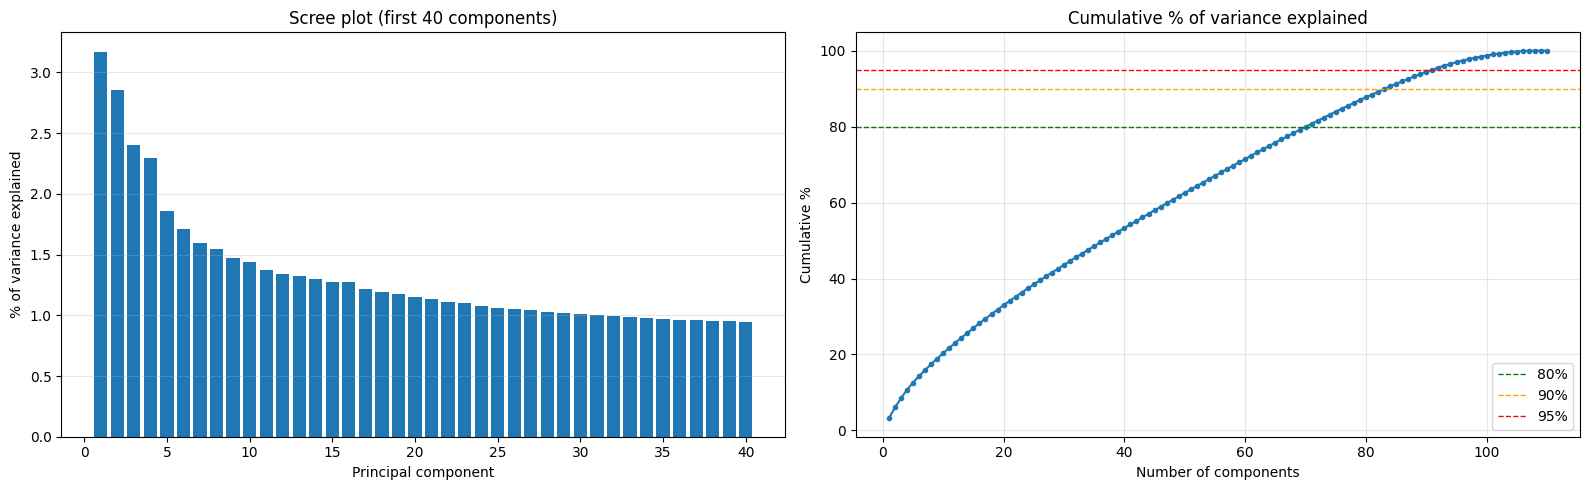


PC1 (3.17% of variance) - top loadings:
change_No             0.397
diabetesMed_Yes      -0.375
n_drugs_prescribed   -0.332
insulin_No            0.254
metformin_No          0.251
metformin_Steady     -0.231
num_medications      -0.225
n_drugs_changed      -0.157

PC2 (2.86% of variance) - top loadings:
max_glu_serum_NotTested     0.429
admission_source_Unknown   -0.416
admission_type_Unknown     -0.409
max_glu_serum_Norm         -0.333
admission_type_Emergency    0.331
max_glu_serum_>300         -0.197
num_lab_procedures          0.157
n_drugs_prescribed         -0.157

PC3 (2.40% of variance) - top loadings:
number_diagnoses                                   0.397
time_in_hospital                                   0.307
num_medications                                    0.293
diag_3_category_Missing                           -0.230
metformin_No                                       0.229
discharge_disposition_Transferred to Other Care    0.226
metformin_Steady                       

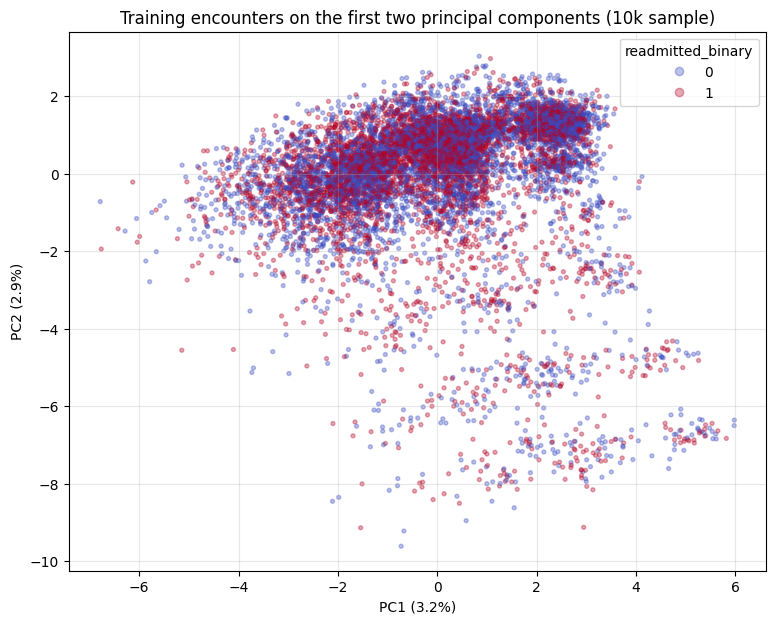

In [ ]:
# ------------------------------------------------------------ 4. Scree plot and cumulative variance
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

n_show = min(40, len(explained))
axes[0].bar(range(1, n_show + 1), explained[:n_show] * 100)
axes[0].set_title(f"Scree plot (first {n_show} components)")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("% of variance explained")
axes[0].grid(axis="y", alpha=0.3)

axes[1].plot(range(1, len(cumulative) + 1), cumulative * 100, marker=".")
for threshold, color in [(80, "green"), (90, "orange"), (95, "red")]:
    axes[1].axhline(threshold, linestyle="--", color=color, linewidth=1, label=f"{threshold}%")
axes[1].set_title("Cumulative % of variance explained")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative %")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------ 5. Which features drive the first components
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=pca_X.columns,
    columns=[f"PC{i + 1}" for i in range(pca_full.n_components_)]
)

for pc in ["PC1", "PC2", "PC3"]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8)
    print(f"\n{pc} ({explained[int(pc[2:]) - 1]:.2%} of variance) - top loadings:")
    print(top.round(3).to_string())

# ------------------------------------------------------------ 6. Do the first two components separate the classes?
X_train_2d = pca_full.transform(X_train_scaled)[:, :2]

sample = np.random.default_rng(SEED).choice(len(X_train_2d), size=min(10000, len(X_train_2d)), replace=False)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    X_train_2d[sample, 0], X_train_2d[sample, 1],
    c=y_train.iloc[sample], cmap="coolwarm", alpha=0.35, s=8
)
plt.legend(*scatter.legend_elements(), title="readmitted_binary")
plt.title("Training encounters on the first two principal components (10k sample)")
plt.xlabel(f"PC1 ({explained[0]:.1%})")
plt.ylabel(f"PC2 ({explained[1]:.1%})")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ------------------------------------------------------------ 7. Final reduced datasets for modelling
VARIANCE_TO_KEEP = 0.90   # change to 0.80 / 0.95 to compare

pca = PCA(n_components=VARIANCE_TO_KEEP, svd_solver="full", random_state=SEED)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
X_train_pca = pd.DataFrame(X_train_pca, index=X_train.index, columns=pc_names)
X_test_pca = pd.DataFrame(X_test_pca, index=X_test.index, columns=pc_names)

print(f"Kept {pca.n_components_} components "
      f"({pca.explained_variance_ratio_.sum():.2%} of variance) "
      f"out of {pca_X.shape[1]} features")
print("X_train_pca:", X_train_pca.shape, "| X_test_pca:", X_test_pca.shape)
display(X_train_pca.head())

Kept 84 components (90.59% of variance) out of 110 features
X_train_pca: (80039, 84) | X_test_pca: (20075, 84)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC75,PC76,PC77,PC78,PC79,PC80,PC81,PC82,PC83,PC84
0,4.052198,-0.368104,-6.941878,-1.952414,3.143220,0.302479,-8.393205,1.873003,-0.048965,4.662003,...,3.032977,-0.192536,0.388297,-2.000537,3.783196,-3.819907,-5.146844,-0.332519,2.250794,-0.398349
1,-0.145762,1.236996,-1.501636,-3.162481,0.755693,1.685584,-1.659385,0.236371,-0.584633,1.817136,...,-1.871508,0.713316,1.245911,2.194792,-2.741879,1.548399,4.963511,-1.314487,-1.270740,0.833295
2,1.027419,0.636146,-2.358946,0.407755,0.038346,1.333828,-0.527768,-0.402339,-2.096447,-1.893736,...,0.458313,-0.210199,-0.254580,0.375497,-0.603879,-0.022565,0.524844,-0.510913,-1.379822,-0.674857
3,-0.282447,0.813268,-0.506143,-1.704080,0.437923,1.154530,0.690489,0.129419,-0.707647,-0.486454,...,-0.216129,0.680579,0.089218,0.068095,0.631891,-0.308895,0.683136,-0.529363,-0.758504,0.273121
4,-0.753591,0.041863,-1.161897,0.820522,0.415576,1.768572,0.008736,-3.649466,-0.160397,2.509556,...,0.247155,0.793003,1.222637,0.726612,-0.318761,0.153368,-0.763308,-0.796088,2.390340,2.026752


## PCA – Results and Findings

### 1. Data used
PCA was fitted on **110 standardised features** (8 numerical features, 2 engineered counts, and dummy-encoded categories including `max_glu_serum` and `A1Cresult`). No constant columns were present.

The dataset was partitioned using a patient-grouped train/test split: **80,039 training encounters** and **20,075 test encounters**. No patient overlaps between groups.

### 2. Variance explained
The variance is distributed broadly across the components, with the first explaining only **3.17%** of the total variance.

| Variance kept | Components needed | Reduction from 110 features |
|---|---:|---:|
| 80% | 71 | 35.5% |
| 90% | 84 | 23.6% |
| 95% | 91 | 17.3% |

The cumulative variance curve shows no distinct elbow point.

### 3. Principal Component Interpretation
* **PC1 (3.17% of variance):** Driven by `change_No` (+0.397), `diabetesMed_Yes` (-0.375), `n_drugs_prescribed` (-0.332), `insulin_No` (+0.254), and `metformin_No` (+0.251). It represents **medication change and intensity**.
* **PC2 (2.86% of variance):** Driven by `max_glu_serum_NotTested` (+0.429), `admission_source_Unknown` (-0.416), and `admission_type_Unknown` (-0.409). It represents **admission source clarity and lab test presence**.
* **PC3 (2.40% of variance):** Driven by `number_diagnoses` (+0.397), `time_in_hospital` (+0.307), and `num_medications` (+0.293). It represents **overall case complexity**.

### 4. Separation of Classes
The 10k random sample visualised on the PC1 and PC2 axes shows that readmitted and non-readmitted encounters overlap completely. The spatial clustering is primarily driven by discrete categorical values (like unknown admission types) mapping to PC2, rather than the binary target class.

### 5. Final Output Matrices
Retaining **90% variance** yields a reduced feature space containing **84 components**:
* `X_train_pca`: (80,039 × 84)
* `X_test_pca`: (20,075 × 84)

# **Data Balancing**

In [ ]:
%%bash
pip install -q imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE
import collections

# Get the multiclass target for the training set using the train_idx from patient-grouped split
y_train_multiclass = patient_df_encoded.iloc[train_idx]["readmitted_multiclass"]

print("Class distribution before SMOTE:")
print(collections.Counter(y_train_multiclass))

# Initialize and apply SMOTE to balance training data
smote = SMOTE(random_state=SEED)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train_multiclass)

print("\nClass distribution after SMOTE:")
print(collections.Counter(y_train_balanced))

print(f"\nBalanced training feature matrix shape: {X_train_balanced.shape}")

Class distribution before SMOTE:
Counter({0: 42623, 2: 28364, 1: 9052})

Class distribution after SMOTE:
Counter({0: 42623, 2: 42623, 1: 42623})

Balanced training feature matrix shape: (127869, 110)


### **Executive Summary - Final Preprocessing & Modeling Strategy Decisions**

#### **1. Core Preprocessing Decisions**
* **Data Leakage Prevention:** Patient encounters are strictly split using `GroupShuffleSplit` on `patient_nbr` (ensuring the train/test overlap is exactly 0). This prevents clinical history leakage from the same patient across splits.
* **Outliers:** Retained entirely. Outlier analysis showed that high hospital utilization metrics (e.g., frequent inpatient, emergency, and outpatient visits) are genuine clinical records that strongly correlate with higher readmission rates.
* **Dimensionality Reduction:** FAMD and PCA were skipped for active modeling. They require too many components (>84 out of 110 encoded features to keep 90% variance) to explain the dataset's variance and show no clear class separation in low-dimensional space. The original sparse features combined with supervised L1 or tree-based feature selection are highly preferred.
* **Class Imbalance:** Handled successfully via SMOTE applied strictly to the training split, bringing the minority classes up to match the majority class count (42,623 encounters for each target class in the training split: class `0` [NO], class `1` [`<30` days], and class `2` [`>30` days]).

#### **2. Multiclass Modeling Options & Strategy**
Given that the target variable `readmitted_multiclass` contains three distinct categories (`0` for NO readmission [53.15%], `1` for `<30` days [11.34%], and `2` for `>30` days [35.50%]), we can evaluate several modeling architectures:

* **Multinomial Logistic Regression (with L1/ElasticNet Penalty):**
  * **Why:** Provides a strong baseline. Since our dataset is highly sparse and wide (due to One-Hot Encoding), applying an L1 penalty acts as an embedded feature selector, keeping the model highly interpretable for clinical use.
* **Random Forest Classifier:**
  * **Why:** Excellent at handling mixed categorical and numerical variables natively. It is robust to outliers and can capture complex, non-linear feature interactions without requiring extensive scaling.
* **XGBoost / LightGBM (Gradient Boosting):**
  * **Why:** Typically yields state-of-the-art predictive performance on tabular datasets. LightGBM, in particular, is highly optimized for wide, sparse binary matrices (like our encoded patient data) and handles class weights or balanced datasets very efficiently.
* **Multi-Layer Perceptron (Neural Network):**
  * **Why:** Can be explored if we wish to map deep interactions among clinical diagnoses and prescribed medications, though it offers less direct clinical interpretability compared to tree-based models.

In [ ]:
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import GroupShuffleSplit
import collections
import numpy as np
import pandas as pd

# Ensure random seed is defined
SEED = 42

# 1. Define the features and the multiclass target from the original patient_df
# Identify columns to drop (IDs, raw diagnoses if mapping is used, and target variants)
drop_cols = ['encounter_id', 'patient_nbr', 'readmitted', 'readmitted_binary', 'readmitted_multiclass', 'readmitted_30', 'target_30']

X_raw = patient_df.drop(columns=[col for col in drop_cols if col in patient_df.columns], errors='ignore').copy()
y_raw = patient_df['readmitted_multiclass'].astype(int)
groups = patient_df['patient_nbr']

# 2. Patient-grouped Train/Test Split on original data
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X_raw, y_raw, groups=groups))

X_train_raw, X_test_raw = X_raw.iloc[train_idx].copy(), X_raw.iloc[test_idx].copy()
y_train_multiclass, y_test_multiclass = y_raw.iloc[train_idx], y_raw.iloc[test_idx]

# Handle missing categories / fillna before passing to SMOTENC
for col in X_train_raw.columns:
    if X_train_raw[col].dtype == 'object' or isinstance(X_train_raw[col].dtype, pd.CategoricalDtype):
        X_train_raw[col] = X_train_raw[col].fillna('Missing').astype(str)
        X_test_raw[col] = X_test_raw[col].fillna('Missing').astype(str)
    else:
        X_train_raw[col] = X_train_raw[col].fillna(X_train_raw[col].median())
        X_test_raw[col] = X_test_raw[col].fillna(X_train_raw[col].median())

# Identify indices of categorical features
categorical_features_indices = [i for i, col in enumerate(X_train_raw.columns)
                                if X_train_raw[col].dtype == 'object'
                                or isinstance(X_train_raw[col].dtype, pd.CategoricalDtype)]

print("Class distribution before SMOTENC:")
print(collections.Counter(y_train_multiclass))

# 3. Apply SMOTENC to the training split
smotenc = SMOTENC(categorical_features=categorical_features_indices, random_state=SEED)
X_train_balanced_raw, y_train_balanced = smotenc.fit_resample(X_train_raw, y_train_multiclass)

print("\nClass distribution after SMOTENC:")
print(collections.Counter(y_train_balanced))

print(f"\nBalanced raw training matrix shape: {X_train_balanced_raw.shape}")

Class distribution before SMOTENC:
Counter({0: 42623, 2: 28364, 1: 9052})


KeyboardInterrupt: 